# Accuracy %99,9, Peki Model İşe Yarıyor mu? Dengesiz Veride Doğru Metrik Seçimi

Medium makalesindeki tüm grafik ve rakamları üreten notebook.

**Veri:** Kredi kartı dolandırıcılığı veri seti — Eylül 2013’te Avrupalı kart sahiplerinin iki günlük 284.807 işlemi (492 dolandırıcılık). ULB Machine Learning Group & Worldline (Dal Pozzolo ve ark., 2015). Not: Veri yaklaşık 100 MB’tır.

**Makale:** Medium linki README’de.

## Kurulum

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASE = Path.cwd()
OUT = BASE / "gorseller"
OUT.mkdir(exist_ok=True)
DATA_URL = ("https://raw.githubusercontent.com/nsethi31/"
            "Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv")

INCELEME_MALIYETI = 5  # Varsayım: her alarmın (şüpheli işaretlenen işlemin) incelenme maliyeti, tutar birimi

# ---------- Görsel stil (seride ortak) ----------
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
LIGHT = "#d9d7cf"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
})


def save(fig, name):
    fig.savefig(OUT / name, dpi=200, bbox_inches="tight", pad_inches=0.35)
    plt.show()


def yuzde(x, d=1):
    return f"%{x * 100:.{d}f}".replace(".", ",")


def binlik(n):
    return f"{n:,}".replace(",", ".")

## 0. Veri ve zamana göre bölme
İlk %70 eğitim, son %30 test.

In [2]:
df = pd.read_csv(DATA_URL)
n, n_fraud = len(df), int(df["Class"].sum())
print(f"Veri: {binlik(n)} işlem, {n_fraud} dolandırıcılık ({yuzde(n_fraud / n, 3)}), "
      f"süre={df.Time.max() / 3600:.0f} saat")

df = df.sort_values("Time").reset_index(drop=True)
i_test = int(n * 0.70)
tr, te = df.iloc[:i_test], df.iloc[i_test:]
FEATS = [c for c in df.columns if c != "Class"]
y_tr, y_te = tr["Class"].values, te["Class"].values
for ad, d in [("eğitim", tr), ("test", te)]:
    print(f"  {ad}: {binlik(len(d))} işlem, {int(d.Class.sum())} dolandırıcılık")

Veri: 284.807 işlem, 492 dolandırıcılık (%0,173), süre=48 saat
  eğitim: 199.364 işlem, 384 dolandırıcılık
  test: 85.443 işlem, 108 dolandırıcılık


## 1. Sınıf dengesizliği

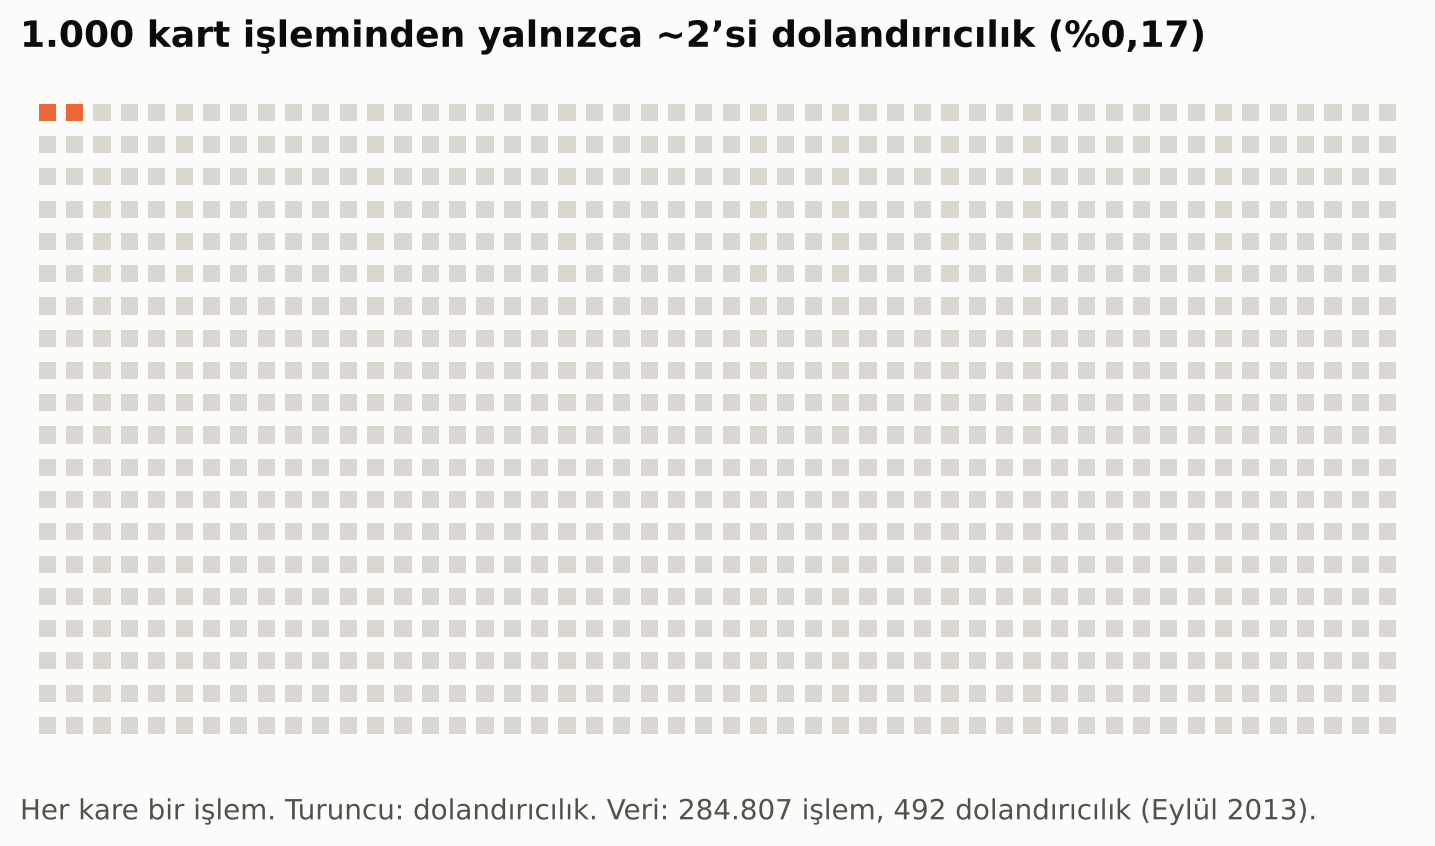

In [3]:
oran_1000 = n_fraud / n * 1000
fig, ax = plt.subplots(figsize=(9, 4.4))
cols, rows = 50, 20
k = round(oran_1000)
xs, ys = np.meshgrid(np.arange(cols), np.arange(rows))
xs, ys = xs.ravel(), ys.ravel()[::-1]
renk = np.array([LIGHT] * (cols * rows), dtype=object)
renk[:k] = ORANGE
ax.scatter(xs, ys, s=38, c=list(renk), marker="s", linewidths=0)
ax.set_xlim(-1, cols); ax.set_ylim(-1, rows)
ax.axis("off")
ax.set_title(f"1.000 kart işleminden yalnızca ~{k}’si dolandırıcılık ({yuzde(n_fraud / n, 2)})", pad=12)
fig.text(0.125, 0.04, f"Her kare bir işlem. Turuncu: dolandırıcılık. Veri: {binlik(n)} işlem, {n_fraud} dolandırıcılık (Eylül 2013).",
         color=INK_2, fontsize=10)
save(fig, "01_sinif_dagilimi.png")

## 2. Üç model: tembel, lojistik regresyon, dengeli lojistik regresyon
Accuracy, recall, precision ve karmaşıklık matrisleri.


[Test seti — üç model]
  Tembel model: accuracy=99.87  recall=0.000  precision=0.000  TN=85335 FP=0 FN=108 TP=0
  Lojistik regresyon: accuracy=99.92  recall=0.491  precision=0.768  TN=85319 FP=16 FN=55 TP=53
  Dengeli lojistik regresyon: accuracy=98.07  recall=0.880  precision=0.055  TN=83695 FP=1640 FN=13 TP=95


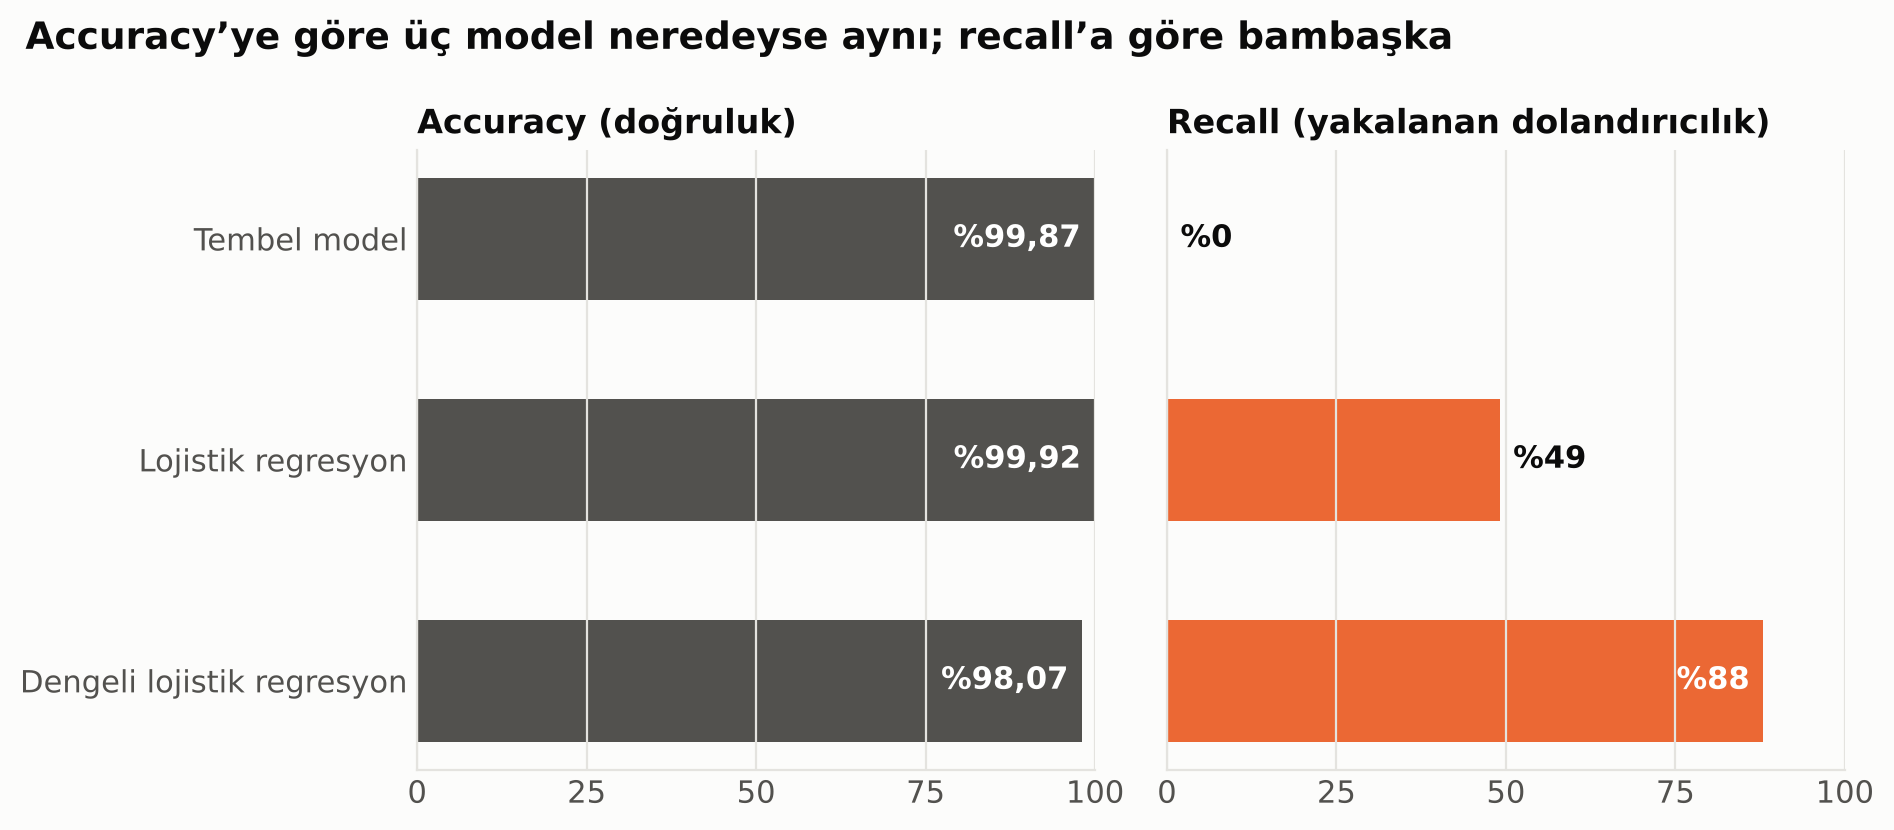

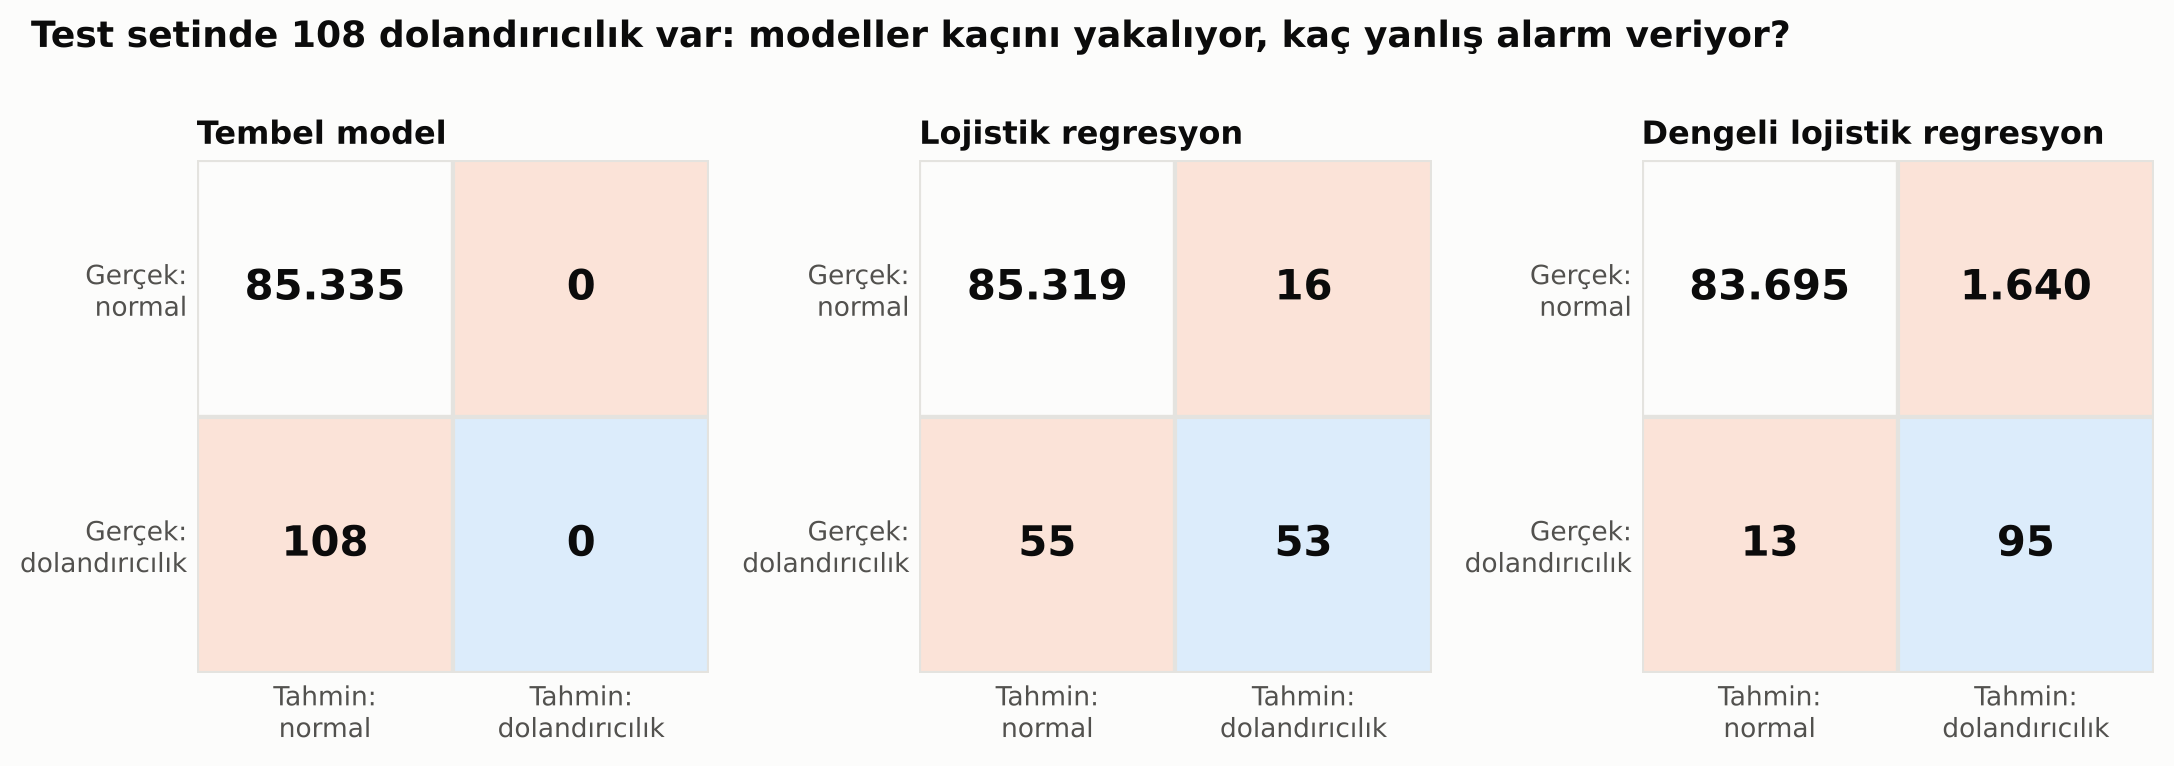

In [4]:
def yeni_model():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))


lr = yeni_model().fit(tr[FEATS], tr["Class"])
lr_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(tr[FEATS], tr["Class"])
p_te = lr.predict_proba(te[FEATS])[:, 1]
pb_te = lr_b.predict_proba(te[FEATS])[:, 1]

modeller = {
    "Tembel model\n(her işleme “normal” der)": np.zeros_like(y_te),
    "Lojistik regresyon\n(eşik 0,5)": (p_te >= 0.5).astype(int),
    "Dengeli lojistik regresyon\n(class_weight=balanced, eşik 0,5)": (pb_te >= 0.5).astype(int),
}
sonuc = {}
print("\n[Test seti — üç model]")
for ad, yp in modeller.items():
    tn, fp, fn, tp = confusion_matrix(y_te, yp, labels=[0, 1]).ravel()
    acc, rec = accuracy_score(y_te, yp), recall_score(y_te, yp, zero_division=0)
    prec = precision_score(y_te, yp, zero_division=0)
    sonuc[ad] = dict(acc=acc, rec=rec, prec=prec, tn=tn, fp=fp, fn=fn, tp=tp)
    print(f"  {ad.splitlines()[0]}: accuracy={acc * 100:.2f}  recall={rec:.3f}  precision={prec:.3f}  "
          f"TN={tn} FP={fp} FN={fn} TP={tp}")

# 2a) Accuracy vs recall çubukları
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2), sharey=True)
etiket = [a.splitlines()[0] for a in modeller]
ypos = np.arange(len(etiket))[::-1]
for ax, key, color, title in [(axes[0], "acc", INK_2, "Accuracy (doğruluk)"),
                              (axes[1], "rec", ORANGE, "Recall (yakalanan dolandırıcılık)")]:
    vals = [sonuc[a][key] for a in modeller]
    ax.barh(ypos, vals, color=color, height=0.55)
    for y_, v in zip(ypos, vals):
        ax.text(min(v, 1) + 0.02 if v < 0.8 else v - 0.02, y_, yuzde(v, 2 if key == "acc" else 0),
                va="center", ha="left" if v < 0.8 else "right",
                color=INK if v < 0.8 else "white", fontsize=11, fontweight="bold")
    ax.set_xlim(0, 1); ax.set_title(title, fontsize=12)
    ax.set_xticks([0, .25, .5, .75, 1]); ax.set_xticklabels(["0", "25", "50", "75", "100"])
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos); axes[0].set_yticklabels(etiket)
fig.suptitle("Accuracy’ye göre üç model neredeyse aynı; recall’a göre bambaşka",
             x=0.02, ha="left", fontsize=13.5, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "02_accuracy_vs_recall.png")

# 2b) Karmaşıklık matrisleri
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, (ad, r) in zip(axes, sonuc.items()):
    m = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    renkler = np.array([[SURFACE, "#fbe3d8"], ["#fbe3d8", "#dcecfb"]])
    for i in range(2):
        for j in range(2):
            ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, facecolor=renkler[i, j], edgecolor=GRID, lw=1.5))
            ax.text(j + .5, 1 - i + .5, binlik(int(m[i, j])), ha="center", va="center",
                    fontsize=15, fontweight="bold", color=INK)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_aspect("equal")
    ax.set_xticks([.5, 1.5]); ax.set_xticklabels(["Tahmin:\nnormal", "Tahmin:\ndolandırıcılık"], fontsize=9.5)
    ax.set_yticks([1.5, .5]); ax.set_yticklabels(["Gerçek:\nnormal", "Gerçek:\ndolandırıcılık"], fontsize=9.5)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(ad.splitlines()[0], fontsize=11.5)
fig.suptitle(f"Test setinde {int(y_te.sum())} dolandırıcılık var: modeller kaçını yakalıyor, kaç yanlış alarm veriyor?",
             x=0.02, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "03_karmasiklik_matrisleri.png")

## 3. ROC ve Precision–Recall eğrisi


[Eğriler] ROC-AUC=0.974  PR-AUC (average precision)=0.705  PR tabanı=0.0013


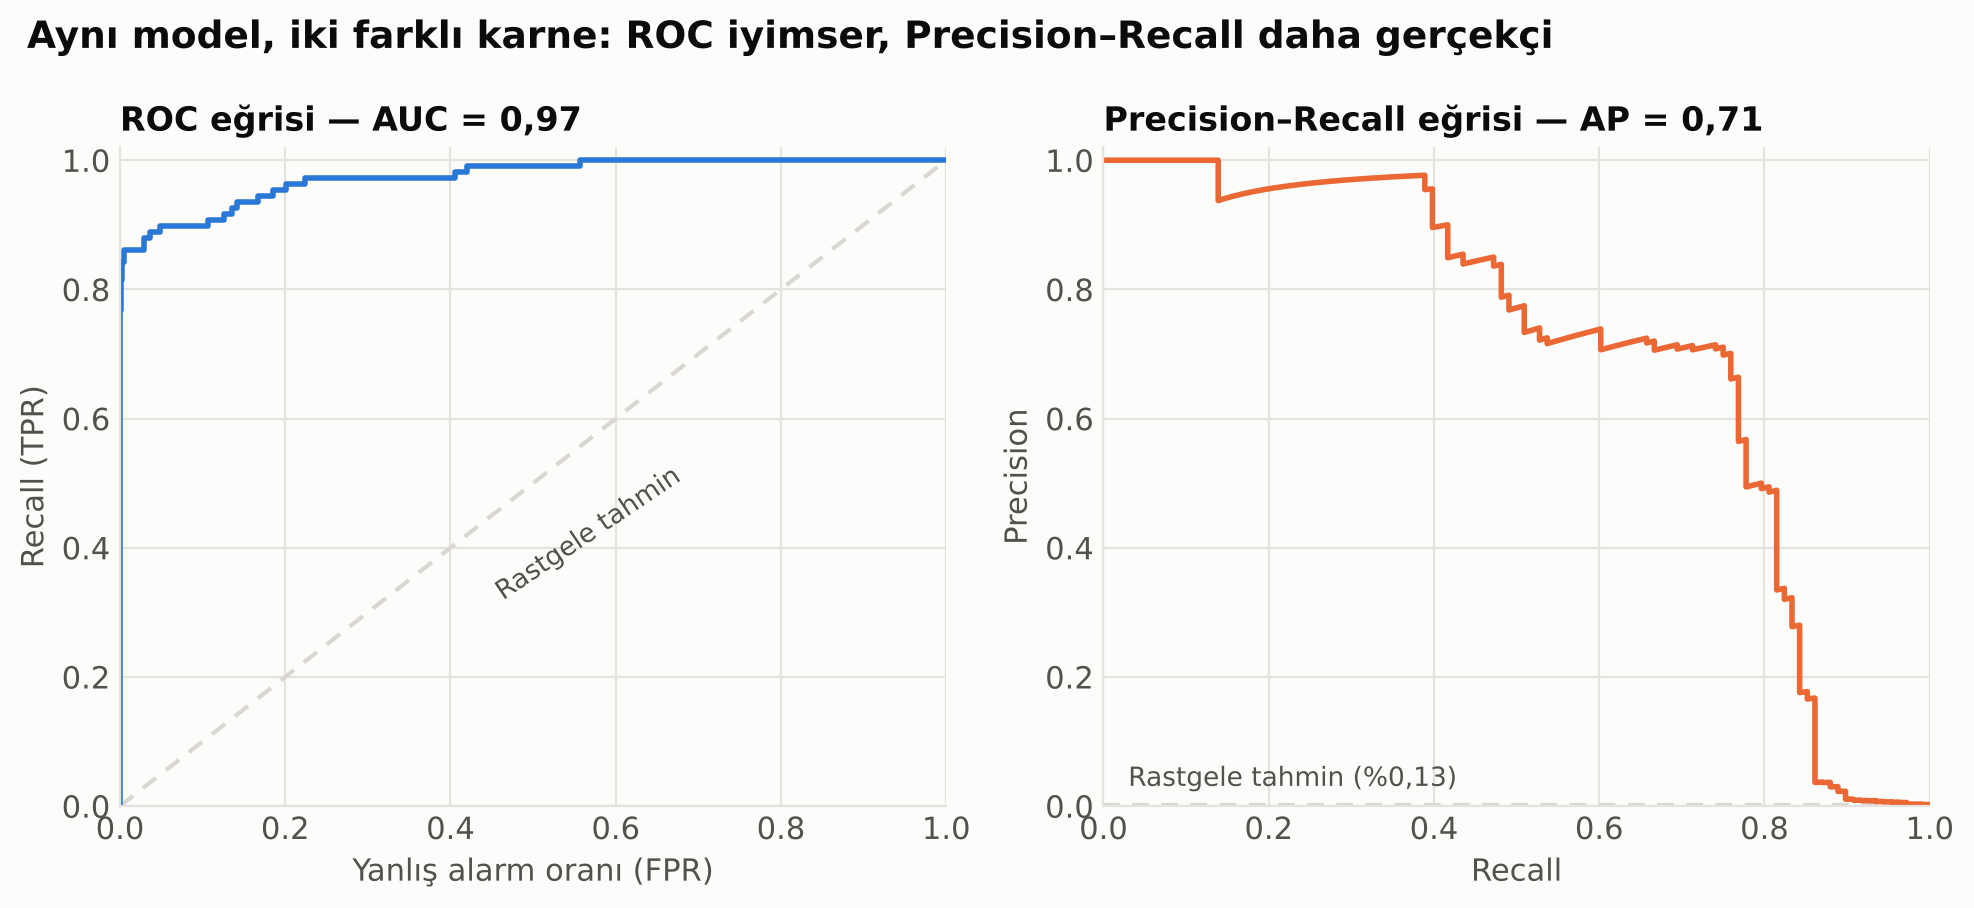

In [5]:
roc_auc, ap = roc_auc_score(y_te, p_te), average_precision_score(y_te, p_te)
taban = y_te.mean()
print(f"\n[Eğriler] ROC-AUC={roc_auc:.3f}  PR-AUC (average precision)={ap:.3f}  PR tabanı={taban:.4f}")
fpr, tpr, _ = roc_curve(y_te, p_te)
pr, rc, _ = precision_recall_curve(y_te, p_te)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
axes[0].plot([0, 1], [0, 1], color=LIGHT, lw=1.5, ls=(0, (4, 3)))
axes[0].plot(fpr, tpr, color=BLUE, lw=2)
axes[0].set_title(f"ROC eğrisi — AUC = {roc_auc:.2f}".replace(".", ","), fontsize=12)
axes[0].set_xlabel("Yanlış alarm oranı (FPR)"); axes[0].set_ylabel("Recall (TPR)")
axes[0].text(0.45, 0.32, "Rastgele tahmin", color=INK_2, fontsize=9.5, rotation=34)
axes[1].axhline(taban, color=LIGHT, lw=1.5, ls=(0, (4, 3)))
axes[1].plot(rc, pr, color=ORANGE, lw=2)
axes[1].set_title(f"Precision–Recall eğrisi — AP = {ap:.2f}".replace(".", ","), fontsize=12)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].text(0.03, taban + 0.03, f"Rastgele tahmin ({yuzde(taban, 2)})", color=INK_2, fontsize=9.5)
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
fig.suptitle("Aynı model, iki farklı karne: ROC iyimser, Precision–Recall daha gerçekçi",
             x=0.02, ha="left", fontsize=13.5, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "04_roc_vs_pr.png")

## 4. Karar eşiği
Eşik, eğitim verisinde zaman sıralı çapraz doğrulamayla (TimeSeriesSplit) maliyet en aza indirilerek seçilir; sonuç test setinde raporlanır. Maliyet varsayımı: kaçan dolandırıcılığın tutarı + alarm başına 5 birim inceleme.


[Eşik seçimi] çapraz doğrulamada 282 dolandırıcılık örneği kullanıldı
[Eşik] seçilen eşik=0.015 (inceleme maliyeti=5)
  eşik 0,5: yakalanan=53/108  yanlış alarm=16  recall=0.491  precision=0.768  kaçan tutar=8708 (toplam dolandırıcılık tutarının %60)  toplam maliyet=8788
  eşik seçilen: yakalanan=90/108  yanlış alarm=204  recall=0.833  precision=0.306  kaçan tutar=2519 (toplam dolandırıcılık tutarının %17)  toplam maliyet=3539
  maliyet düşüşü: %60
  duyarlılık (farklı inceleme maliyeti varsayımları):
    maliyet=2: eşik=0.015  test maliyeti=2927  (0,5 eşiğinde 8740)  düşüş=%67
    maliyet=5: eşik=0.015  test maliyeti=3539  (0,5 eşiğinde 8788)  düşüş=%60
    maliyet=10: eşik=0.03  test maliyeti=3883  (0,5 eşiğinde 8868)  düşüş=%56


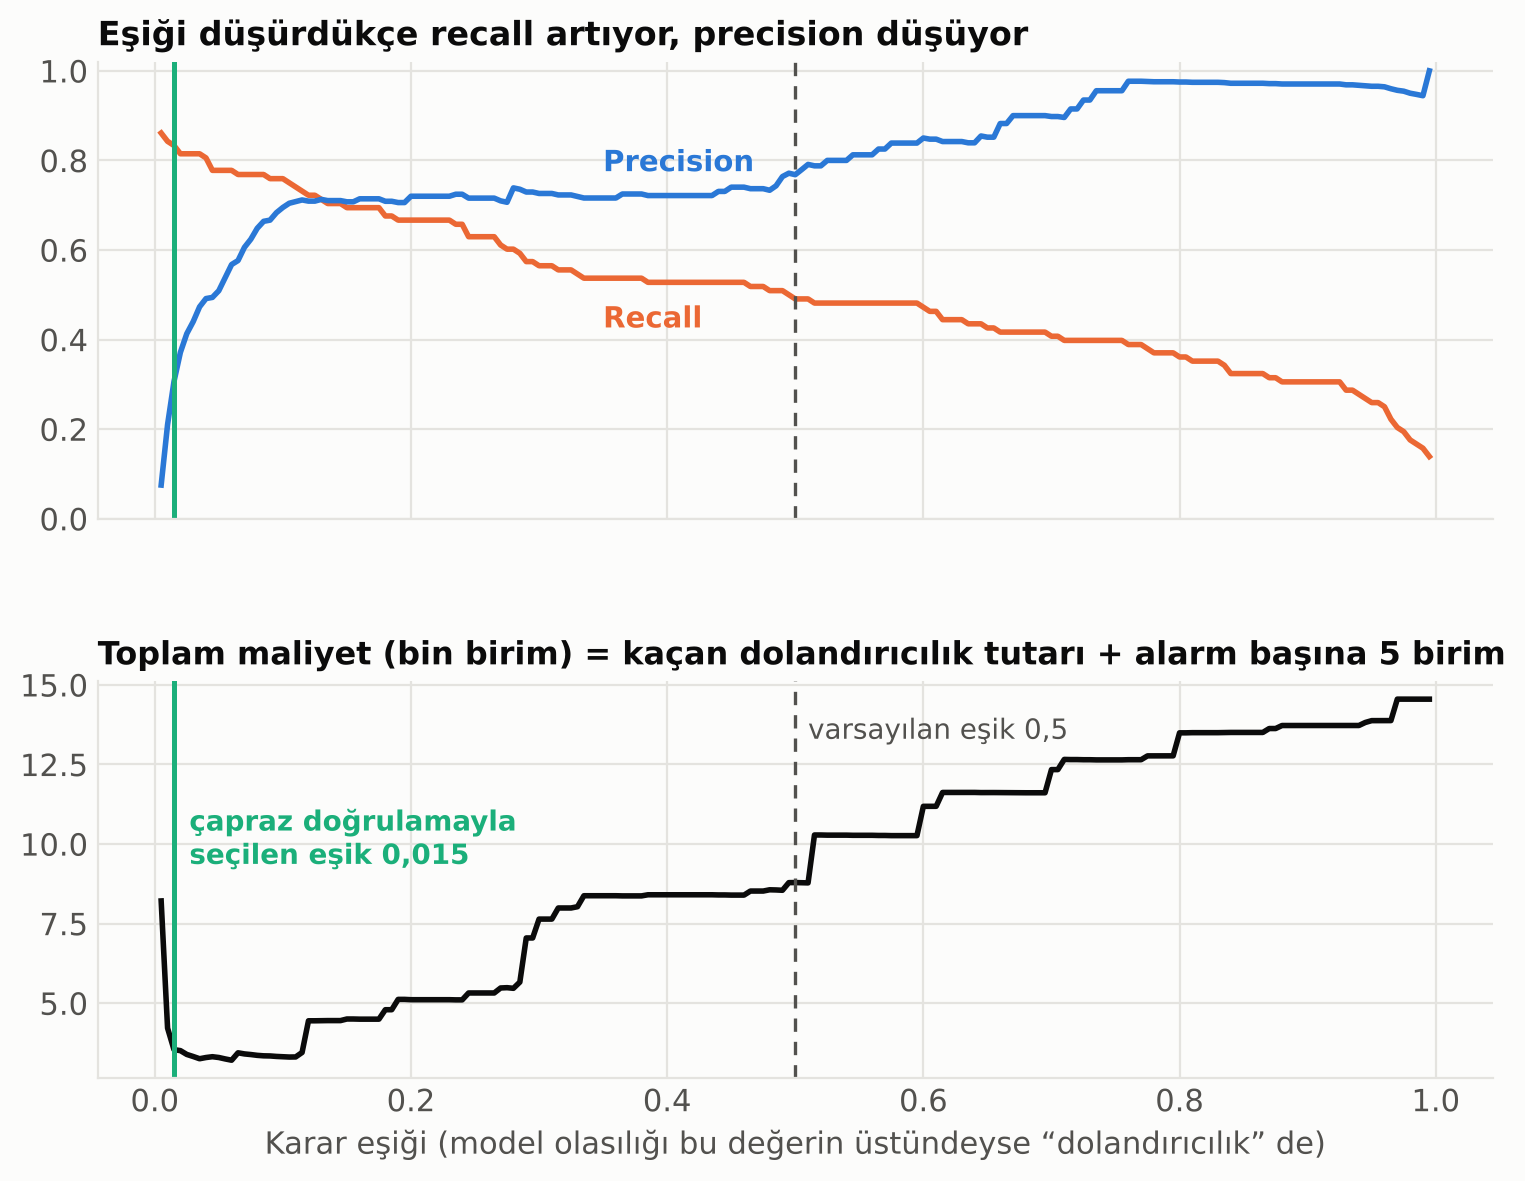


Görseller: gorseller/ klasörüne kaydedildi


In [6]:
esikler = np.round(np.arange(0.005, 0.996, 0.005), 3)


def maliyet(y, p, amt, t):
    yp = p >= t
    kacan = (y == 1) & ~yp
    alarm_yanlis = (y == 0) & yp
    return amt[kacan].sum() + INCELEME_MALIYETI * alarm_yanlis.sum()


# Zaman sıralı çapraz doğrulama: her kat yalnızca kendinden önceki veriyle eğitilir
oof = np.full(len(tr), np.nan)
for i_a, i_b in TimeSeriesSplit(n_splits=5).split(tr):
    oof[i_b] = yeni_model().fit(tr.iloc[i_a][FEATS], tr.iloc[i_a]["Class"]).predict_proba(tr.iloc[i_b][FEATS])[:, 1]
mask = ~np.isnan(oof)
y_cv, p_cv, amt_cv = y_tr[mask], oof[mask], tr["Amount"].values[mask]
amt_te = te["Amount"].values


def esik_sec(c):
    global INCELEME_MALIYETI
    eski, INCELEME_MALIYETI = INCELEME_MALIYETI, c
    t = float(esikler[np.argmin([maliyet(y_cv, p_cv, amt_cv, t) for t in esikler])])
    INCELEME_MALIYETI = eski
    return t


t_sec = esik_sec(INCELEME_MALIYETI)
print(f"\n[Eşik seçimi] çapraz doğrulamada {int(y_cv.sum())} dolandırıcılık örneği kullanıldı")

def ozet(t):
    yp = (p_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, yp, labels=[0, 1]).ravel()
    return dict(t=t, tp=int(tp), fn=int(fn), fp=int(fp), rec=tp / (tp + fn), prec=tp / (tp + fp),
                kacan_tutar=float(amt_te[(y_te == 1) & (yp == 0)].sum()),
                maliyet=float(maliyet(y_te, p_te, amt_te, t)))

toplam_fraud_tutar = float(amt_te[y_te == 1].sum())
o05, osec = ozet(0.5), ozet(t_sec)
print(f"[Eşik] seçilen eşik={t_sec} (inceleme maliyeti={INCELEME_MALIYETI})")
for ad, o in [("0,5", o05), ("seçilen", osec)]:
    print(f"  eşik {ad}: yakalanan={o['tp']}/{o['tp'] + o['fn']}  yanlış alarm={o['fp']}  recall={o['rec']:.3f}  "
          f"precision={o['prec']:.3f}  kaçan tutar={o['kacan_tutar']:.0f} "
          f"(toplam dolandırıcılık tutarının {yuzde(o['kacan_tutar'] / toplam_fraud_tutar, 0)})  toplam maliyet={o['maliyet']:.0f}")
print(f"  maliyet düşüşü: {yuzde(1 - osec['maliyet'] / o05['maliyet'], 0)}")
print("  duyarlılık (farklı inceleme maliyeti varsayımları):")
for c in [2, 5, 10]:
    t_c = esik_sec(c)
    eski, INCELEME_MALIYETI = INCELEME_MALIYETI, c
    m_c, m_05 = maliyet(y_te, p_te, amt_te, t_c), maliyet(y_te, p_te, amt_te, 0.5)
    INCELEME_MALIYETI = eski
    print(f"    maliyet={c}: eşik={t_c}  test maliyeti={m_c:.0f}  (0,5 eşiğinde {m_05:.0f})  düşüş={yuzde(1 - m_c / m_05, 0)}")

prec_t = [precision_score(y_te, p_te >= t, zero_division=0) for t in esikler]
rec_t = [recall_score(y_te, p_te >= t) for t in esikler]
c_te = np.array([maliyet(y_te, p_te, amt_te, t) for t in esikler])

fig, axes = plt.subplots(2, 1, figsize=(9, 6.6), sharex=True, gridspec_kw=dict(height_ratios=[1.15, 1], hspace=0.38))
ax = axes[0]
ax.plot(esikler, rec_t, color=ORANGE, lw=2, label="Recall")
ax.plot(esikler, prec_t, color=BLUE, lw=2, label="Precision")
ax.set_ylim(0, 1.02); ax.set_title("Eşiği düşürdükçe recall artıyor, precision düşüyor", fontsize=12)
i35 = int(np.searchsorted(esikler, 0.35))
ax.text(0.35, rec_t[i35] - 0.11, "Recall", color=ORANGE, fontsize=10.5, fontweight="bold")
ax.text(0.35, prec_t[i35] + 0.06, "Precision", color=BLUE, fontsize=10.5, fontweight="bold")
ax2 = axes[1]
ax2.plot(esikler, c_te / 1000, color=INK, lw=2)
ax2.set_title(f"Toplam maliyet (bin birim) = kaçan dolandırıcılık tutarı + alarm başına {INCELEME_MALIYETI} birim", fontsize=11.5)
ax2.set_xlabel("Karar eşiği (model olasılığı bu değerin üstündeyse “dolandırıcılık” de)")
for a in axes:
    a.axvline(0.5, color=INK_2, lw=1.2, ls=(0, (4, 3)))
    a.axvline(t_sec, color=AQUA, lw=1.8)
ax2.text(0.51, ax2.get_ylim()[1] * 0.88, "varsayılan eşik 0,5", color=INK_2, fontsize=10)
ax2.text(t_sec + 0.012, ax2.get_ylim()[1] * 0.62, f"çapraz doğrulamayla\nseçilen eşik {t_sec:.3f}".replace(".", ","), color=AQUA, fontsize=10, fontweight="bold")
save(fig, "05_esik_secimi.png")

print("\nGörseller: gorseller/ klasörüne kaydedildi")